<a href="https://colab.research.google.com/github/2026CT05085/085_ML-Assignment2/blob/main/2026CT05085_MLAssignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Table of Contents
1. [Importing Libraries](#Importing-Libraries)
2. [Dataset Loading & Directory Creation](#Dataset-Loading)
3. [Data Cleaning & Target Exploration](#Data-Cleaning)
4. [Feature Engineering & Split](#Feature-Split)
5. [Preprocessing Pipelines](#Preprocessing)
6. [Model Setup](#Model-Setup)
7. [Model Training & Evaluation](#Model-Training)
8. [Model Comparison & Visualization](#Model-Comparison)
9. [Best Model Selection](#Best-Model)

**ML Assignment 2:** The objective of this project is to implement and compare multiple machine learning classification algorithms to predict whether a bank customer will subscribe to a term deposit.

Five classification algorithms are implemented and evaluated using six performance metrics.

### Name: PRANAYJIT MAHATA
### ID: 2026CT05085

<a id='Dataset-Loading'></a>
## 1. Dataset Loading

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

In [ ]:
# Create output directories
os.makedirs("model", exist_ok=True)
os.makedirs("results", exist_ok=True)

# 1. Load dataset
df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

Dataset shape: (45211, 17)

First five records:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  


<a id='Data-Cleaning'></a>
## 2. Data Cleaning & Target Exploration


Duplicate records: 0

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


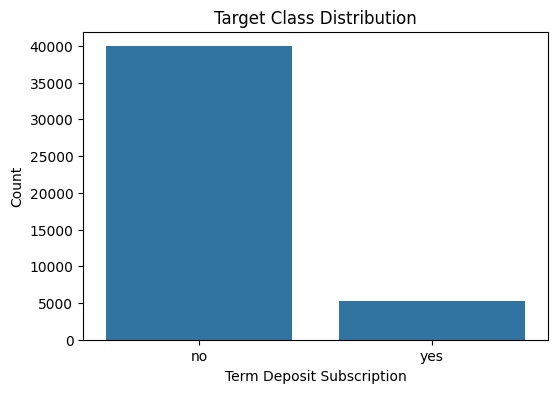

In [ ]:
# 2. Remove duplicate records
print("\nDuplicate records:", df.duplicated().sum())
df = df.drop_duplicates()

# 3. Identify missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Separate features and target
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

# Check target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Count")
plt.savefig("results/class_distribution.png")
plt.show()


<a id='Feature-Split'></a>
## 3. Feature Engineering & Split

In [ ]:
# 5. Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

# 6. Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Save test data
test_data = X_test.copy()
test_data["y"] = y_test.map({0: "no", 1: "yes"})
test_data.to_csv("test_data.csv", index=False)


Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


<a id='Preprocessing'></a>
## 4. Preprocessing Pipelines

In [ ]:
# 7. Define Preprocessing Pipelines
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

<a id='Model-Setup'></a>
## 5. Model Setup

In [ ]:
# 8. Define Classification Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

<a id='Model-Training'></a>
## 6. Model Training & Evaluation

In [ ]:
# 9. Train and Evaluate Models
results = []

for name, model in models.items():
    print("\nTraining:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    # Save trained model
    filename = name.lower().replace(" ", "_")
    joblib.dump(pipeline, f"model/{filename}.joblib")

    print("Accuracy:", accuracy)
    print("AUC:", auc)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)
    print("MCC:", mcc)


Training: Logistic Regression
Accuracy: 0.901249585314608
AUC: 0.9055740146044154
Precision: 0.6444833625218914
Recall: 0.34782608695652173
F1 Score: 0.4518109269490485
MCC: 0.42605817794513523

Training: Decision Tree
Accuracy: 0.8745991374543846
AUC: 0.7014571863832587
Precision: 0.46487985212569316
Recall: 0.47542533081285443
F1 Score: 0.4700934579439252
MCC: 0.39902087033749317

Training: KNN
Accuracy: 0.8961627778392126
AUC: 0.8277209275898927
Precision: 0.5990016638935108
Recall: 0.34026465028355385
F1 Score: 0.43399638336347196
MCC: 0.40012752249162636

Training: Naive Bayes
Accuracy: 0.8548048214088245
AUC: 0.8100945416322902
Precision: 0.4059040590405904
Recall: 0.5198487712665406
F1 Score: 0.45586406962287607
MCC: 0.37735837569864067

Training: Random Forest
Accuracy: 0.9044564856795311
AUC: 0.926285639543899
Precision: 0.6506211180124224
Recall: 0.3960302457466919
F1 Score: 0.49236192714453586
MCC: 0.45972400148255543


<a id='Model-Comparison'></a>
## 7. Model Comparison & Visualization


MODEL COMPARISON
           ML Model  Accuracy      AUC  Precision   Recall  F1 Score      MCC
Logistic Regression  0.901250 0.905574   0.644483 0.347826  0.451811 0.426058
      Decision Tree  0.874599 0.701457   0.464880 0.475425  0.470093 0.399021
                KNN  0.896163 0.827721   0.599002 0.340265  0.433996 0.400128
        Naive Bayes  0.854805 0.810095   0.405904 0.519849  0.455864 0.377358
      Random Forest  0.904456 0.926286   0.650621 0.396030  0.492362 0.459724


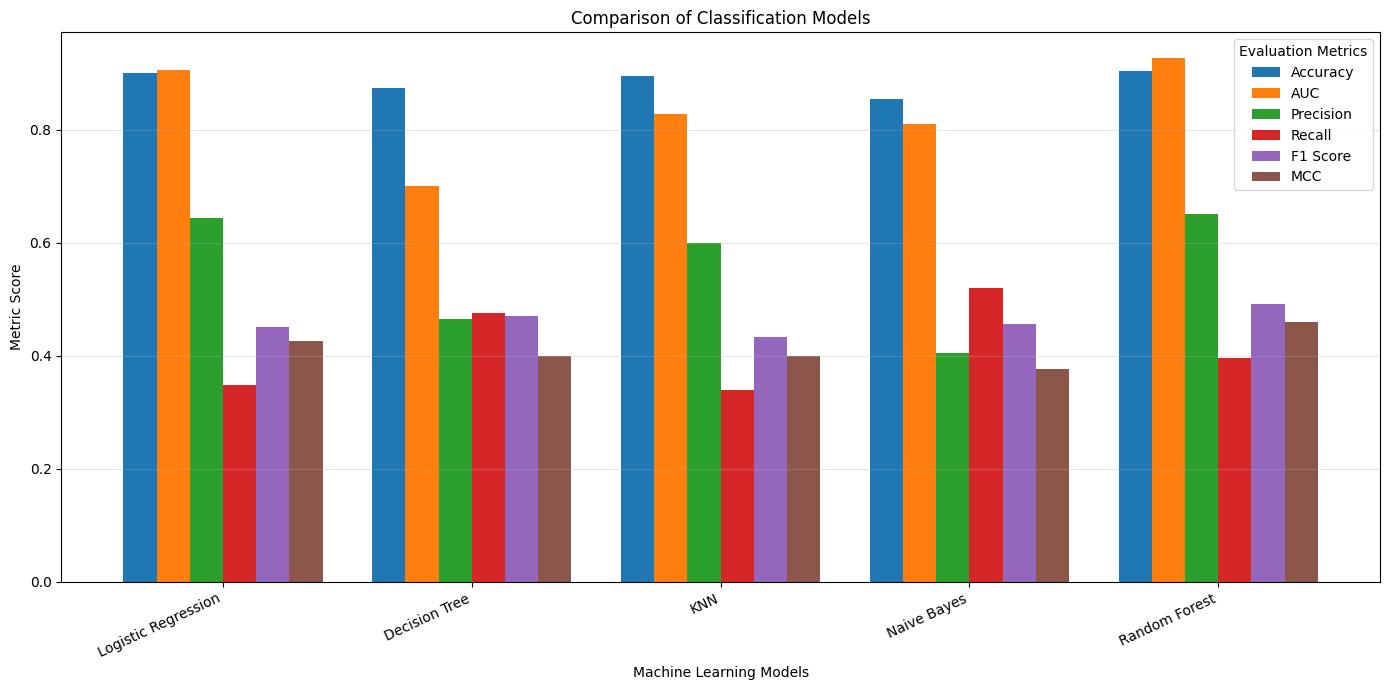

In [ ]:
# 10. Model Comparison and Visualization
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

# Visualize all evaluation metrics
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]
plot_data = results_df.set_index("ML Model")[metrics]

plot_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Comparison of Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metric Score")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("results/model_comparison.png")
plt.show()

### 8. Observations on model performance

| ML Model | Observation about model performance |
| :--- | :--- |
| **Logistic Regression** | Provides a baseline classification approach. It achieves an F1 score of **0.452** and an AUC of **0.906**, indicating its ability to distinguish between the two classes. |
| **Decision Tree** | Captures nonlinear relationships between features. Its performance is reflected by an accuracy of **0.875** and an MCC of **0.399**. |
| **KNN** | Classifies observations based on their nearest neighbours. Its performance depends on feature scaling and the selected number of neighbours. |
| **Naive Bayes** | Uses probability-based classification and assumes conditional independence between features. Its performance is reflected in its precision and recall scores. |
| **Random Forest** | Combines multiple decision trees to improve prediction stability. Its F1 score of **0.492** and AUC of **0.926** indicate its classification performance. |

<a id='Best-Model'></a>
## 9. Best Model Selection

In [ ]:
# 11. Identify the Best Model
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("\nOVERALL WINNER BASED ON F1 SCORE")
print(best_model)



OVERALL WINNER BASED ON F1 SCORE
ML Model     Random Forest
Accuracy          0.904456
AUC               0.926286
Precision         0.650621
Recall             0.39603
F1 Score          0.492362
MCC               0.459724
Name: 4, dtype: object


## 10. Overall winner

"The overall best-performing model was **Random Forest**, which achieved the highest F1 score of **0.492**. It demonstrated a comparatively effective balance between precision and recall. The model was selected based on its performance on the test dataset. MCC and AUC were also considered to assess classification quality and class discrimination."